In [1]:
%matplotlib inline
from dataclasses import dataclass
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator

import susi.io.load_output_data as load_output
from susi.io.load_output_data import (
    NetcdfVariablePath,
    OutputDataStore,
    ScenarioID,
    StandID,
)

In [2]:
# Relative to this notebook, so the same path works locally and on CSC
RUN_PATH = Path("outputs/run_01").resolve()

# Same numbering as MAP_SPECIES_NUMBER in run.py
SPECIES_NAMES = {1: "pine", 2: "spruce", 3: "other"}

# Order of every x axis: the order of create_scenarios() in run.py.
# Scenarios of older runs are not listed here and go last, sorted by name.
DRAINAGE_SCENARIOS = [
    "DD60-60_NS",
    "DD60-60_S",
    "DD90-90_S",
    "WM30-30_S",
    "WM60-10_S",
    "WM30-10_S",
]

# The levels of the `canopy_layer` column of the results table, in plotting
# order. "stand" is the whole stand, the other two are its canopy layers.
# The `under` layer is left out because no wq_rosa stand has it.
CANOPY_LAYERS = ["dominant", "subdominant"]
LEVELS = ["stand", *CANOPY_LAYERS]

# Site fertility class is ordinal, hence one hue from light to dark.
# A fixed mapping, so a class keeps its color whatever slice is plotted.
SITE_FERTILITY_CLASS_COLORS = {3: "#6fb1dc", 4: "#2b7bba", 5: "#0f3f6e"}

# Read data


In [3]:
@dataclass(frozen=True)
class PlottedVariable:
    """
    One value column of the results table: where it is in the netcdf at the
    stand level and at the canopy layer level. To plot a new variable, add
    one of these to VARIABLES below.
    """

    column: str  # Name of the column in the results table
    label: str  # Axis label
    stand_path: NetcdfVariablePath  # e.g. /stand/volume
    layer_variable_name: str  # e.g. volume, for /stand/<layer>/volume
    # True if the layer variable is per tree: it is then multiplied by the
    # layer's stems to get the per hectare value. /stand/<layer>/volume is one
    # of these, and the sum of volume x stems over the layers is /stand/volume.
    layer_value_is_per_tree: bool


VOLUME = PlottedVariable(
    column="volume",
    label="Volume [m³/ha]",
    stand_path=NetcdfVariablePath("/stand/volume"),
    layer_variable_name="volume",
    layer_value_is_per_tree=True,
)
VARIABLES = [VOLUME]


def layer_path(layer: str, variable_name: str) -> NetcdfVariablePath:
    return NetcdfVariablePath(f"/stand/{layer}/{variable_name}")


def netcdf_paths_to_read(variables: list[PlottedVariable]) -> list[NetcdfVariablePath]:
    """Every netcdf variable the results table needs, including the stems."""
    paths = [layer_path(layer, "stems") for layer in CANOPY_LAYERS]
    for variable in variables:
        paths.append(variable.stand_path)
        for layer in CANOPY_LAYERS:
            paths.append(layer_path(layer, variable.layer_variable_name))
    return paths


def dominant_species(simulation: pd.Series) -> str:
    """
    Species of a simulation's dominant layer. The netcdf variable
    /scen/tree_species_dominant is empty, so it comes from the parameters:
    the pointers give one allometry registry key per soil column, and
    wq_rosa has one allometry per layer, so the first pointer is enough.
    """
    allometry = "stand_params.canopy_layer_allometry"
    registry_key = simulation[f"{allometry}.pointers.dominant"][0]
    species_id = simulation[f"{allometry}.allometry_file_registry.{registry_key}.species_id"]
    return SPECIES_NAMES[int(species_id)]


def simulations_table(metadata_by_stand: dict[StandID, pd.DataFrame]) -> pd.DataFrame:
    """
    One row per simulation (stand x scenario) with the columns the plots group by.
    Every table below starts from this one, so its columns are the shared vocabulary.
    """
    metadata = pd.concat(metadata_by_stand.values(), ignore_index=True)
    return pd.DataFrame(
        {
            "stand_id": metadata["stand_id"],
            "scenario_id": metadata["scenario_id"],
            # A fertilized scenario has the drainage of its twin plus the ash,
            # so the two share a drainage_scenario and differ in `fertilized`
            "drainage_scenario": metadata["scenario_id"].str.removesuffix("_ash"),
            # Read from the parameters, not from the name: old runs have no _ash suffix
            "fertilized": metadata["site_parameters.fertilization.fertilizer_dose"].notna(),
            "region": metadata["tags.region"],
            "site_fertility_class": metadata["stand_params.site_fertility_class"],
            "dominant_species": metadata.apply(dominant_species, axis=1),
            # The pointers of a layer the stand does not have are null
            "has_subdominant_layer": metadata[
                "stand_params.canopy_layer_allometry.pointers.subdominant"
            ].notna(),
            "start_year": pd.to_datetime(metadata["simulation_config.start_date"]).dt.year,
        }
    )


def load_run(
    run_path: Path, variables: list[NetcdfVariablePath]
) -> tuple[OutputDataStore, pd.DataFrame]:
    """
    The only function that touches the output files: every netcdf file is opened
    once and all `variables` are read in that single pass. Opening is the slow
    part (~90 ms per file, see issue #359), so list every variable you may want
    to plot here rather than calling this again for each one.
    """
    metadata_by_stand = load_output.load_all_metadatas_from_stands(
        folders=load_output.list_stand_folders(run_dirpath=run_path)
    )
    # metadata.json holds the path the netcdf was written to, which is wrong
    # if the run folder has been moved since. Trust the folder we are reading.
    for stand_id, metadata in metadata_by_stand.items():
        metadata["netcdf_output_filepath"] = [
            run_path / stand_id / scenario_id / filename
            for scenario_id, filename in zip(
                metadata["scenario_id"], metadata["netcdf_output_filename"]
            )
        ]
    store = load_output.read_netcdf_files_for_selected_variables_from_metadatas(
        selected_variables=variables, metadata_by_stand=metadata_by_stand
    )
    return store, simulations_table(metadata_by_stand)


def values_per_column(
    store: OutputDataStore,
    variable_path: NetcdfVariablePath,
    stand_id: StandID,
    scenario_id: ScenarioID,
) -> np.ndarray:
    """
    The (year x soil column) array of a variable, ditches excluded. The years
    a simulation never wrote come masked: they turn into NaN, so that the
    completeness check below can count them.
    """
    array = store.get_variable_value_for_scenario_and_stand(
        variable_path=variable_path, stand_id=stand_id, scenario_id=scenario_id
    )
    return np.ma.filled(array.processed.astype(float), np.nan)


def yearly_spatial_mean(
    store: OutputDataStore,
    variable: PlottedVariable,
    level: str,
    stand_id: StandID,
    scenario_id: ScenarioID,
) -> np.ndarray:
    """One value per year: the mean over the soil columns, at one level of LEVELS."""
    if level == "stand":
        return values_per_column(store, variable.stand_path, stand_id, scenario_id).mean(axis=1)

    values = values_per_column(
        store, layer_path(level, variable.layer_variable_name), stand_id, scenario_id
    )
    if variable.layer_value_is_per_tree:
        values = values * values_per_column(store, layer_path(level, "stems"), stand_id, scenario_id)
    return values.mean(axis=1)


def results_table(
    store: OutputDataStore,
    simulations: pd.DataFrame,
    variables: list[PlottedVariable],
) -> pd.DataFrame:
    """
    Every plot starts from this one tidy table. One row per simulation, year and
    level (the `canopy_layer` column), one column per variable. Slicing is then
    a matter of naming columns in row=, col= and hue=.

    A stand without a subdominant layer has no subdominant rows, instead of
    rows full of zeros.

    Row i of the netcdf is the state at the start of year start_year + i
    (row 0 is the initial state).
    """
    tables = []
    for simulation in simulations.itertuples(index=False):
        levels = LEVELS if simulation.has_subdominant_layer else ["stand", "dominant"]
        for level in levels:
            values = {
                variable.column: yearly_spatial_mean(
                    store, variable, level, simulation.stand_id, simulation.scenario_id
                )
                for variable in variables
            }
            n_years = len(next(iter(values.values())))
            years = simulation.start_year + np.arange(n_years)
            # Scalar columns (stand_id, region, ...) are broadcast to every year
            tables.append(
                pd.DataFrame({**simulation._asdict(), "canopy_layer": level, "year": years, **values})
            )
    return pd.concat(tables, ignore_index=True)


def drainage_scenario_order(simulations: pd.DataFrame) -> list[str]:
    """The drainage scenarios present in the run, in the order of DRAINAGE_SCENARIOS."""
    present = set(simulations["drainage_scenario"])
    known = [name for name in DRAINAGE_SCENARIOS if name in present]
    return known + sorted(present - set(DRAINAGE_SCENARIOS))


def scenario_order(simulations: pd.DataFrame, drainage_order: list[str]) -> list[ScenarioID]:
    """Every scenario once: the unfertilized ones first, each group in drainage order."""
    scenarios = simulations[["scenario_id", "drainage_scenario", "fertilized"]].drop_duplicates()
    positions = {name: position for position, name in enumerate(drainage_order)}
    scenarios = scenarios.assign(position=scenarios["drainage_scenario"].map(positions))
    return list(scenarios.sort_values(["fertilized", "position"])["scenario_id"])


def print_scenarios(scenario_ids: list[ScenarioID]) -> None:
    print(f"All {len(scenario_ids)} scenarios: {', '.join(scenario_ids)}")

In [4]:
store, simulations = load_run(run_path=RUN_PATH, variables=netcdf_paths_to_read(VARIABLES))
table = results_table(store=store, simulations=simulations, variables=VARIABLES)

DRAINAGE_ORDER = drainage_scenario_order(simulations)
ALL_SCENARIOS = scenario_order(simulations, DRAINAGE_ORDER)
table

,stand_id,scenario_id,drainage_scenario,fertilized,region,site_fertility_class,dominant_species,has_subdominant_layer,start_year,canopy_layer,year,volume
0,197690,ash_fertilization,ash_fertilization,True,pirkanmaa,4,pine,False,2004,stand,2004,153.239700
1,197690,ash_fertilization,ash_fertilization,True,pirkanmaa,4,pine,False,2004,stand,2005,153.239700
2,197690,ash_fertilization,ash_fertilization,True,pirkanmaa,4,pine,False,2004,stand,2006,153.239700
3,197690,ash_fertilization,ash_fertilization,True,pirkanmaa,4,pine,False,2004,stand,2007,154.950546
4,197690,ash_fertilization,ash_fertilization,True,pirkanmaa,4,pine,False,2004,stand,2008,154.950546
...,...,...,...,...,...,...,...,...,...,...,...,...
2911,20338237,control,control,False,pirkanmaa,3,pine,True,2004,subdominant,2017,49.062261
2912,20338237,control,control,False,pirkanmaa,3,pine,True,2004,subdominant,2018,49.062261
2913,20338237,control,control,False,pirkanmaa,3,pine,True,2004,subdominant,2019,49.302437
2914,20338237,control,control,False,pirkanmaa,3,pine,True,2004,subdominant,2020,49.302437


# Stand counts
How many stands there are in each category. It counts stands, not simulations: every stand has one simulation per scenario.

The lines below the table say whether the run is complete: a missing simulation or a simulation with NaN years would otherwise just vanish from the plots.

In [5]:
def stand_count_table(simulations: pd.DataFrame) -> pd.DataFrame:
    """
    Stands per region and site fertility class, split by dominant species,
    with a total row per region and one for the whole run.
    """
    # All the stand-level columns are the same in each of a stand's scenarios
    stands = simulations.drop_duplicates("stand_id")
    groups = ["region", "site_fertility_class"]
    counts = pd.crosstab(
        index=[stands["region"], stands["site_fertility_class"]],
        columns=stands["dominant_species"],
    )
    counts.columns.name = None
    counts["total"] = counts.sum(axis=1)
    counts["with subdominant layer"] = stands.groupby(groups)["has_subdominant_layer"].sum()

    # Each region's classes followed by the region's total
    sections = []
    for region, region_counts in counts.groupby(level="region"):
        region_total = region_counts.sum().to_frame(name=(region, "total")).T
        sections.extend([region_counts, region_total])
    run_total = counts.sum().to_frame(name=("all regions", "total")).T
    return pd.concat([*sections, run_total]).rename_axis(index=groups)


def print_completeness(simulations: pd.DataFrame, table: pd.DataFrame) -> None:
    """Says how far the run is from one simulation per stand and scenario."""
    n_stands = simulations["stand_id"].nunique()
    n_scenarios = simulations["scenario_id"].nunique()
    n_expected = n_stands * n_scenarios
    print(
        f"{len(simulations)} simulations found, {n_expected} expected "
        f"({n_stands} stands x {n_scenarios} scenarios)"
    )
    value_columns = [variable.column for variable in VARIABLES]
    with_nans = table[table[value_columns].isna().any(axis=1)]
    n_with_nans = len(with_nans.drop_duplicates(["stand_id", "scenario_id"]))
    print(f"{n_with_nans} simulations with NaN years")


print_completeness(simulations=simulations, table=table)
print_scenarios(ALL_SCENARIOS)
stand_count_table(simulations=simulations)

60 simulations found, 60 expected (20 stands x 3 scenarios)
0 simulations with NaN years
All 3 scenarios: DNM_80, control, ash_fertilization


pine  spruce  total  with subdominant layer
region      site_fertility_class                                             
pirkanmaa   3                        2       1      3                       3
            4                        6       0      6                       3
            5                        1       0      1                       1
            total                    9       1     10                       7
pohjanmaa   3                        2       1      3                       3
            4                        5       0      5                       4
            5                        2       0      2                       0
            total                    9       1     10                       7
all regions total                   18       2     20                      14

# Per-stand values over time, one scenario at a time
Pick the scenario in the dropdown: it drives both figures, and the Y axes stay fixed while you flip through scenarios, so a change you see is a change in the data.

The first figure uses the stand-level variable (`/stand/volume`):
- Subplot columns: the two regions
- Y axis is a variable (e.g., volume), X axis is time (years)
- One line per stand. Each point is the spatial mean of the variable (in case of volume: per hectare volume, not weighted by stand area)
- The hue is the site fertility class

The second figure separates the stand by canopy layer:
- Subplot rows: the two regions. Subplot columns: the dominant and subdominant layers
- Each layer's volume is per hectare (`/stand/<layer>/volume` is per tree, so it is multiplied by `/stand/<layer>/stems`)
- Stands without a subdominant layer are not in the subdominant subplots. The subplot titles give the number of stands

To slice it differently, change the `row=`, `col=` and `hue=` of the calls in `show_scenario`, using any column of `table`. A `palette` only applies to its own `hue`, so remove it when changing the hue.

In [6]:
def add_stand_counts_to_titles(
    grid: sns.FacetGrid, data: pd.DataFrame, facet_columns: list[str]
) -> None:
    """
    Appends each subplot's number of stands to its title.
    facet_columns are the columns the grid is split by: first row, then col.
    """
    for facet_values, ax in grid.axes_dict.items():
        # The keys are tuples only when the grid has both a row and a col
        if not isinstance(facet_values, tuple):
            facet_values = (facet_values,)
        subset = data
        for column, value in zip(facet_columns, facet_values):
            subset = subset[subset[column] == value]
        # Smaller than the default, or the titles of neighbouring subplots collide
        ax.set_title(f"{ax.get_title()} ({subset['stand_id'].nunique()} stands)", fontsize="medium")


def facet_columns_of(seaborn_options: dict) -> list[str]:
    return [seaborn_options[name] for name in ("row", "col") if name in seaborn_options]


def make_legend_opaque(grid: sns.FacetGrid) -> None:
    """Legend entries inherit the marks' transparency, which leaves them too faint to read."""
    if grid.legend is None:
        return
    for handle in grid.legend.legend_handles:
        handle.set_alpha(1)
        handle.set_linewidth(2)


def plot_lines(
    data: pd.DataFrame, variable: PlottedVariable, **seaborn_options
) -> sns.FacetGrid:
    """One line per stand over time. seaborn_options go to sns.relplot: row, col, hue, ..."""
    # units + estimator=None: one line per stand instead of a mean with a band
    grid = sns.relplot(
        data=data,
        kind="line",
        x="year",
        y=variable.column,
        units="stand_id",
        estimator=None,
        linewidth=0.7,
        alpha=0.5,
        height=3.5,
        aspect=1.5,
        **seaborn_options,
    )
    grid.set_axis_labels("Year", variable.label)
    add_stand_counts_to_titles(grid, data, facet_columns_of(seaborn_options))
    make_legend_opaque(grid)
    # Whole years only (default ticks give 2007.5)
    for ax in grid.axes.flat:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    return grid


def show_scenario(scenario_id: ScenarioID) -> None:
    print(f"Showing {scenario_id}")
    print_scenarios(ALL_SCENARIOS)
    data = table[table["scenario_id"] == scenario_id]

    stand_level = data[data["canopy_layer"] == "stand"]
    grid = plot_lines(
        data=stand_level,
        variable=VOLUME,
        col="region",
        hue="site_fertility_class",
        palette=SITE_FERTILITY_CLASS_COLORS,
    )
    # Fixed over all the scenarios, see y_limits below
    grid.set(ylim=(0, y_limits["stand"]))

    layers = data[data["canopy_layer"].isin(CANOPY_LAYERS)]
    grid = plot_lines(
        data=layers,
        variable=VOLUME,
        row="region",
        col="canopy_layer",
        col_order=CANOPY_LAYERS,
        hue="site_fertility_class",
        palette=SITE_FERTILITY_CLASS_COLORS,
        # Regions share a scale within a layer. Sharing it across the layers
        # would squash the much smaller subdominant volumes.
        facet_kws={"sharey": "col"},
    )
    for (_, layer), ax in grid.axes_dict.items():
        ax.set_ylim(0, y_limits[layer])
    plt.show()


# Highest value of each level over all the scenarios
y_limits = table.groupby("canopy_layer")[VOLUME.column].max() * 1.05

widgets.interact(
    show_scenario,
    scenario_id=widgets.Dropdown(options=ALL_SCENARIOS, description="Scenario"),
);

interactive(children=(Dropdown(description='Scenario', options=('DNM_80', 'control', 'ash_fertilization'), val…

# Final volume per scenario, region and fertilization
Figure shows the per-stand <variable> in the last simulated year, and its mean:
- Y axis is a variable (e.g., volume), X axis has one tick per drainage scenario
- Subplot columns: the two regions, sharing the Y axis
- Subplot rows: without fertilization, and with it. A fertilized scenario has the same drainage as the unfertilized one above it, plus the ash
- Each point is a single stand. The hue is its site fertility class
- The black tick is the mean over all the stands of the subplot's scenario (not weighted by stand area)

The classes are dodged, so read the points as three strips per scenario. The share of each class differs between regions, so part of a difference between the regions' means can come from that mix.

All 3 scenarios: DNM_80, control, ash_fertilization


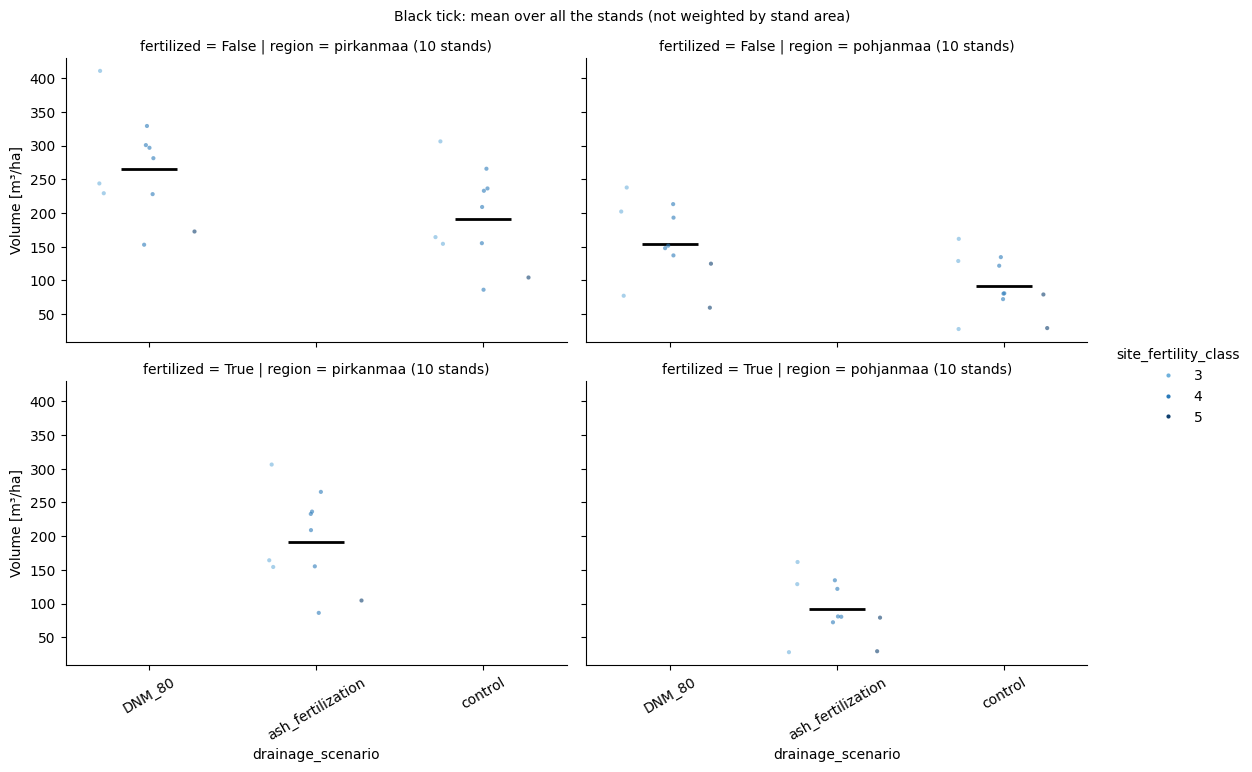

In [7]:
def last_year_rows(table: pd.DataFrame) -> pd.DataFrame:
    """The rows of each simulation's last simulated year."""
    last_year = table.groupby(["stand_id", "scenario_id"])["year"].transform("max")
    return table[table["year"] == last_year]


def plot_strips_with_mean(
    data: pd.DataFrame,
    variable: PlottedVariable,
    x: str,
    order: list[str],
    **seaborn_options,
) -> sns.FacetGrid:
    """
    One point per stand and a black tick at the mean of each x value.
    seaborn_options go to sns.catplot: row, col, hue, ...
    """
    grid = sns.catplot(
        data=data,
        kind="strip",
        x=x,
        y=variable.column,
        order=order,
        dodge=True,
        size=3,
        alpha=0.6,
        height=3.5,
        aspect=1.6,
        **seaborn_options,
    )
    # One mean per subplot and x value, over every hue
    grid.map_dataframe(
        sns.pointplot,
        x=x,
        y=variable.column,
        order=order,
        estimator="mean",
        errorbar=None,
        linestyle="none",
        marker="_",
        markersize=40,
        markeredgewidth=2,
        color="black",
    )
    grid.set_axis_labels(x, variable.label)
    add_stand_counts_to_titles(grid, data, facet_columns_of(seaborn_options))
    make_legend_opaque(grid)
    grid.tick_params(axis="x", rotation=30)
    # The tick is not in the legend, and the figure gets read away from this notebook
    grid.figure.suptitle(
        "Black tick: mean over all the stands (not weighted by stand area)",
        y=1.02,
        fontsize="medium",
    )
    return grid


print_scenarios(ALL_SCENARIOS)
final_stand_values = last_year_rows(table[table["canopy_layer"] == "stand"])
plot_strips_with_mean(
    data=final_stand_values,
    variable=VOLUME,
    x="drainage_scenario",
    order=DRAINAGE_ORDER,
    row="fertilized",
    row_order=[False, True],
    col="region",
    hue="site_fertility_class",
    palette=SITE_FERTILITY_CLASS_COLORS,
);